# SUN RGB-D data preparation (dataset v2)

This notebook documents and validates the training data of the thesis:
instance segmentation of the standard 10 SUN RGB-D classes with Mask R-CNN,
with depth kept for the 3D part (chapter 3).

**Single source of truth.** The COCO file and all splits are produced by the
CLI `utils/prepare_dataset.py` (functions `build_coco` / `make_splits`, which
call `utils/sunrgbd.py`). This notebook **loads those outputs** and explains them;
it never re-draws a split on its own. Setting `REBUILD = True` re-runs exactly
the CLI functions (the frozen `split_assignment.csv` is kept, so the result is
identical); by default it only reads. Running it is idempotent.

```bash
# from the repository root (see CLAUDE.md "Useful commands")
python utils/prepare_dataset.py --root <SUNRGBD> --out notebooks/outputs \
    --classes standard10 --fresh-split          # COCO + std10 split (once)
python utils/prepare_dataset.py --coco notebooks/outputs/sunrgbd_instances_all.json \
    --out notebooks/outputs --min-instances 400 --splits-name splits_min400 \
    --base-assignment notebooks/outputs/splits/split_assignment.csv
```

**What changed in v2** (all models are retrained on it):

1. proper polygon clipping to the image (Sutherland–Hodgman) instead of
   per-vertex clamping;
2. recovered class names (compound names, typos, descriptive modifiers);
3. leak-free grouping: SUN3D sites, simultaneous multi-sensor captures,
   capture sessions of the timestamped collections, kv1 near-duplicates;
4. a fresh group-level stratified 70/15/15 split (seed 42).

Contents: 1) dataset overview · 2) sensors, resolutions, intrinsics · 3) depth
decoding · 4) annotation parsing and name normalization · 5) polygon clipping ·
6) COCO file, class and size distributions · 7) leak-free grouping ·
8) stratified split · summary.

In [1]:
import json, random, sys
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pycocotools import mask as mask_utils

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import utils.sunrgbd as sd
import utils.prepare_dataset as pdp

DATASET_ROOT = Path("/Users/polina_sushko/My_work/University/ВКР/SUNRGBD")
OUT_DIR      = Path("outputs")
CONFIGS      = {"std10": OUT_DIR / "splits", "min400": OUT_DIR / "splits_min400",
                "min100": OUT_DIR / "splits_min100"}
SEED         = 42
REBUILD      = False   # True: re-run the CLI functions (same result, ~5 min)

# Colors (fixed roles, as in 01b_class_analysis.ipynb)
C_STD, C_ADD, C_DROP, C_OTHER = "#2a78d6", "#1baf7a", "#eb6834", "#b6b4ad"
SUBSET_COLORS = {"train": "#2a78d6", "val": "#1baf7a", "test": "#eda100"}
C_TEXT, C_TEXT2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e6e1", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9.5,
    "axes.titlesize": 11, "axes.titleweight": "bold",
    "text.color": C_TEXT, "axes.labelcolor": C_TEXT2,
    "xtick.color": C_TEXT2, "ytick.color": C_TEXT2,
})

def savefig(fig, name):
    fig.savefig(OUT_DIR / name, dpi=150, bbox_inches="tight")

if REBUILD:
    pdp.build_coco(DATASET_ROOT, OUT_DIR, 200.0, 8.0, True,
                   id_map=pdp.load_image_ids([OUT_DIR / "sunrgbd_instances_all.json"]))
    pdp.make_splits(OUT_DIR / "sunrgbd_instances_all.json", OUT_DIR, 10,
                    list(sd.STANDARD_10_CLASSES), 0.15, 0.15, SEED)
    for name, mi, base in (("splits_min400", 400, "splits"), ("splits_min100", 100, "splits_min400")):
        pdp.make_splits(OUT_DIR / "sunrgbd_instances_all.json", OUT_DIR, 10, [], 0.15, 0.15,
                        SEED, min_instances=mi, splits_name=name,
                        base_assignment=OUT_DIR / base / "split_assignment.csv")

coco = json.loads((OUT_DIR / "sunrgbd_instances_all.json").read_text())
cat_name = {c["id"]: c["name"] for c in coco["categories"]}
print(f"Dataset version: {coco['info'].get('version')}; images {len(coco['images'])}, "
      f"instances {len(coco['annotations'])}, categories {len(coco['categories'])}")

Dataset version: v2; images 10294, instances 125239, categories 8662


---
## 1. Dataset overview

SUN RGB-D (10,335 RGB-D frames) merges several earlier datasets captured with four
sensors: Kinect v1 (NYU Depth v2, B3DO), Kinect v2, Asus Xtion (SUN3D video scans
and a separate aligned set) and Intel RealSense. Scenes are found by their
`image/` folder (`sd.find_scenes`); depth comes from `depth_bfx` (inpainted)
where available.

In [2]:
scenes = sd.find_scenes(DATASET_ROOT, require_annotation=False)
img_by_key = {im["rel_key"]: im for im in coco["images"]}
group_of = {im["rel_key"]: im["group_key"] for im in coco["images"]}

rows = []
for s in scenes:
    intr = sd.read_intrinsics(s.intrinsics_path)
    with Image.open(s.rgb_path) as im:
        w, h = im.size
    rows.append({
        "rel_key": s.rel_key, "group_key": group_of.get(s.rel_key, ""),
        "sensor": s.sensor, "collection": s.collection, "scene_type": s.scene_type,
        "width": w, "height": h, "has_annotation": s.annotation_path is not None,
        "has_intrinsics": intr is not None,
        "fx": intr.fx if intr else None, "fy": intr.fy if intr else None,
        "cx": intr.cx if intr else None, "cy": intr.cy if intr else None,
        "n_instances": 0, "depth_source": getattr(s, "depth_source", ""),
        "in_coco": s.rel_key in img_by_key,
    })
scan_df = pd.DataFrame(rows).set_index("rel_key")
n_inst = Counter(a["image_id"] for a in coco["annotations"])
for key, im in img_by_key.items():
    scan_df.loc[key, "n_instances"] = n_inst[im["id"]]
scan_df.reset_index().to_csv(OUT_DIR / "scenes_index.csv", index=False)

print(f"Scenes: {len(scan_df)}; annotated: {scan_df.has_annotation.sum()}; "
      f"with intrinsics: {scan_df.has_intrinsics.sum()}; in the COCO file "
      f"(>= 1 usable object): {scan_df.in_coco.sum()}")
overview = (scan_df.groupby(["sensor", "collection"])
            .agg(scenes=("in_coco", "size"), in_coco=("in_coco", "sum"),
                 depth_bfx=("depth_source", lambda s: (s == "depth_bfx").sum()))
            .reset_index())
display(overview)

Scenes: 10335; annotated: 10335; with intrinsics: 10335; in the COCO file (>= 1 usable object): 10294


,sensor,collection,scenes,in_coco,depth_bfx
0,kv1,NYUdata,1449,1449,1449
1,kv1,b3dodata,554,551,554
2,kv2,align_kv2,299,299,299
3,kv2,kinect2data,3485,3474,3485
4,realsense,lg,548,544,548
5,realsense,sa,439,433,439
6,realsense,sh,21,20,21
7,realsense,shr,151,151,151
8,xtion,sun3ddata,3090,3074,3090
9,xtion,xtion_align_data,299,299,299


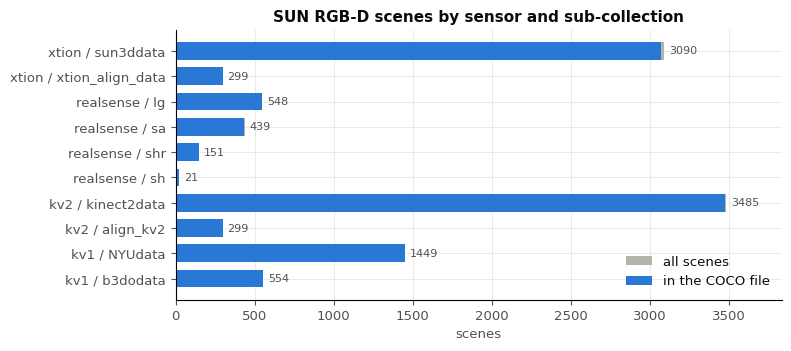

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ov = overview.sort_values(["sensor", "scenes"])
labels = [f"{s} / {c}" for s, c in zip(ov.sensor, ov.collection)]
ax.barh(labels, ov.scenes, color=C_OTHER, height=0.7, label="all scenes")
ax.barh(labels, ov.in_coco, color=C_STD, height=0.7, label="in the COCO file")
for y, v in enumerate(ov.scenes.values):
    ax.text(v + 30, y, f"{v}", va="center", fontsize=8, color=C_TEXT2)
ax.set_xlabel("scenes"); ax.set_title("SUN RGB-D scenes by sensor and sub-collection")
ax.legend(frameon=False, loc="lower right"); ax.margins(x=0.1)
plt.tight_layout(); savefig(fig, "fig_dataset_overview.png"); plt.show()

---
## 2. Sensors, resolutions and intrinsics

Every sensor has its own resolution and focal length, so the intrinsics are read
**per scene** (`intrinsics.txt`), never as one constant — this matters for the
back-projection to 3D in chapter 3.

In [4]:
res = (scan_df.assign(resolution=scan_df.width.astype(str) + "x" + scan_df.height.astype(str))
       .groupby("sensor").agg(scenes=("resolution", "size"),
                              resolutions=("resolution", lambda s: ", ".join(
                                  f"{r} ({n})" for r, n in s.value_counts().head(3).items()))))
intr = scan_df[scan_df.has_intrinsics].groupby("sensor")[["fx", "fy", "cx", "cy"]].agg(["mean", "std"]).round(1)
display(res); display(intr)

,scenes,resolutions
sensor,,
kv1,2003,561x427 (2003)
kv2,3784,730x530 (3784)
realsense,1159,681x531 (1159)
xtion,3389,591x441 (3389)


fx           fy           cx          cy     
            mean   std   mean   std   mean  std   mean  std
sensor                                                     
kv1        519.3   0.7  519.8   0.6  282.7  3.0  210.5  2.9
kv2        529.5   0.0  529.5   0.0  365.0  0.0  265.0  0.0
realsense  693.7   0.3  693.7   0.3  360.5  0.3  264.8  0.0
xtion      567.0  10.7  567.0  10.7  308.3  5.4  225.5  1.7

---
## 3. Depth decoding

SUN RGB-D stores depth as 16-bit PNG with the three low bits rotated to the top:
the value in millimetres is `(raw >> 3) | (raw << 13)` (`sd.decode_depth`).
Reading the PNG directly (`raw / 1000`) gives a plausible-looking but wrong map —
values roughly 8× too large with wrap-around noise. Values above 8 m or 0 are
treated as missing.

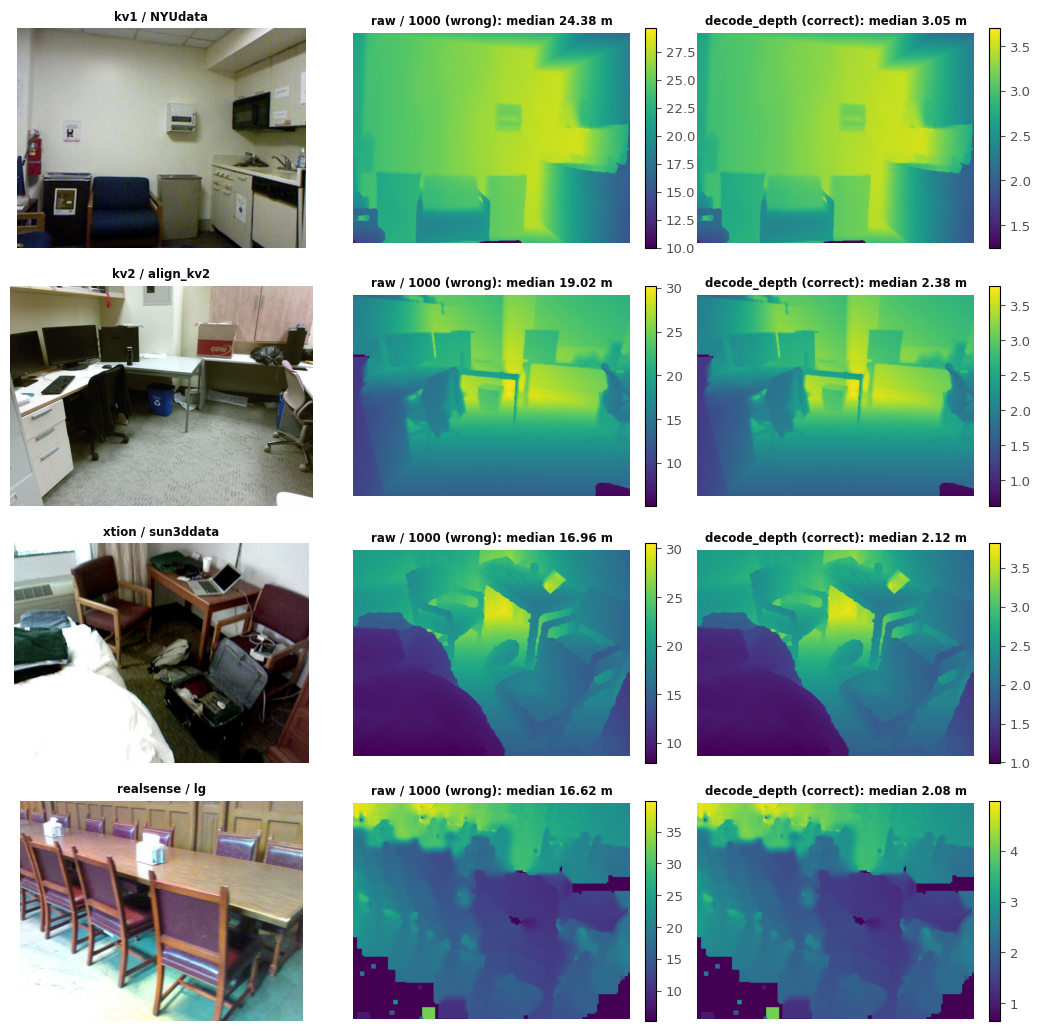

valid_ratio       median_m      
                 mean count     mean count
sensor                                    
kv1             1.000    42    2.358    42
kv2             1.000    74    2.179    74
realsense       1.000    22    2.076    22
xtion           0.992    62    2.301    62

In [5]:
demo_keys = [next(k for k, im in sorted(img_by_key.items()) if im["sensor"] == s)
             for s in ("kv1", "kv2", "xtion", "realsense")]
fig, axes = plt.subplots(len(demo_keys), 3, figsize=(10.5, 2.6 * len(demo_keys)))
for row, key in zip(axes, demo_keys):
    im = img_by_key[key]
    raw = np.array(Image.open(DATASET_ROOT / im["depth_file"]))
    raw = raw[..., 0] if raw.ndim == 3 else raw
    for ax, data, title in ((row[1], raw.astype(np.float32) / 1000.0, "raw / 1000 (wrong)"),
                            (row[2], sd.decode_depth(raw), "decode_depth (correct)")):
        valid = data[data > 0]
        h_ = ax.imshow(np.ma.masked_where(data <= 0, data), cmap="viridis")
        ax.set_title(f"{title}: median {np.median(valid):.2f} m", fontsize=8.5)
        fig.colorbar(h_, ax=ax, fraction=0.04)
    row[0].imshow(sd.read_rgb(DATASET_ROOT / im["file_name"]))
    row[0].set_title(f"{im['sensor']} / {im['collection']}", fontsize=8.5)
    for ax in row:
        ax.axis("off")
plt.tight_layout(); savefig(fig, "fig_depth_decoding.png"); plt.show()

# depth completeness on a seeded sample of the COCO images
sample = random.Random(SEED).sample(sorted(img_by_key), 200)
depth_rows = []
for key in sample:
    d = sd.read_depth(DATASET_ROOT / img_by_key[key]["depth_file"]); v = d > 0
    depth_rows.append({"sensor": img_by_key[key]["sensor"], "valid_ratio": float(v.mean()),
                       "median_m": float(np.median(d[v])) if v.any() else np.nan})
depth_df = pd.DataFrame(depth_rows)
depth_df.to_csv(OUT_DIR / "depth_stats_sample.csv", index=False)
display(depth_df.groupby("sensor")[["valid_ratio", "median_m"]].agg(["mean", "count"]).round(3))

---
## 4. Annotation parsing and name normalization

The 2D annotations (`annotation2Dfinal/index.json`, LabelMe-like) hold one entry
per object with a free-text name and one or more polygons. Names were typed by
hand, so `sd.normalize_name()` maps them to canonical classes:

1. lower case, `_` → space, edge punctuation (`chair.`, `|keyboard`) and trailing
   indices (`chair 3`) removed;
2. `SYNONYMS` (`couch` → sofa, `night stand` → nightstand, ...), also matched
   with spaces/hyphens removed and with a plural `s` stripped (`coffeetables`);
3. **v2:** reviewed compound names and typos of the std10 / min400 classes
   (`roundtable`, `loveseat`, `computerchair`, `tabel`, `recyclebin`, ...);
4. **v2:** purely descriptive modifiers in front of a class word — colour,
   material, size, shape, position, ordinal, article (`whiteleathersofa`,
   `2ndchair`, `smallcoffeetable`); never for ambiguous heads (`bin`, `tub`,
   `screen`, `pc`, `cpu`).

Every candidate name was reviewed; the decisions (mapped or not, with the reason)
are in `outputs/class_analysis/name_recovery_v2.csv` and are regression-checked
in `01b_class_analysis.ipynb`. Desk-like "X table", desk/table combinations,
dressing table, sofa set / sofa bed, stools, benches, ottomans, counters, object
parts and groups are deliberately **not** mapped. "Stuff" categories (wall,
floor, ceiling, ...) are dropped, as are objects with mask area < 200 px or a
bounding-box side < 8 px.

In [6]:
raw_objects = []          # (rel_key, W, H, raw name, normalized name, polygons)
for s in scenes:
    if s.annotation_path is None or s.rel_key not in img_by_key:
        continue
    im = img_by_key[s.rel_key]
    for obj in sd.load_annotations(s.annotation_path):
        raw_objects.append((s.rel_key, im["width"], im["height"], obj.raw_name, obj.name, obj.polygons))

raw_counts = Counter((r[3].strip(), r[4]) for r in raw_objects)
name_map = (pd.DataFrame([(raw, norm, n) for (raw, norm), n in raw_counts.items()],
                         columns=["raw_name", "normalized", "count"])
            .sort_values(["normalized", "count"], ascending=[True, False]))
name_map.to_csv(OUT_DIR / "name_normalization_map.csv", index=False)
print(f"Annotated objects (scenes in the COCO file): {len(raw_objects)}; distinct raw "
      f"names: {name_map.raw_name.str.lower().nunique()} -> normalized: {name_map.normalized.nunique()}")
std_map = name_map[name_map.normalized.isin(sd.STANDARD_10_CLASSES)]
print(f"Raw spellings folded into the standard 10 classes: {len(std_map)}")
display(std_map.groupby("normalized").agg(spellings=("raw_name", "size"), objects=("count", "sum"),
        examples=("raw_name", lambda s: ", ".join(s.head(6)))).reindex(sd.STANDARD_10_CLASSES))

Annotated objects (scenes in the COCO file): 173499; distinct raw names: 11224 -> normalized: 9351
Raw spellings folded into the standard 10 classes: 850


,spellings,objects,examples
normalized,,,
bed,33,1489,"bed, Bed, BED, bunkbed, BunkBed, bed2"
chair,302,19505,"chair, Chair, CHAIR, chairs, chair2, armchair"
sofa,114,2341,"sofa, couch, Couch, Sofa, SOFA, loveseat"
table,175,8110,"table, Table, TABLE, coffeetable, sidetable, e..."
desk,109,2754,"desk, Desk, DESK, studentdesk, computerdesk, d..."
toilet,8,275,"toilet, Toilet, TOILET, WesternToilet, WESTERN..."
dresser,42,727,"dresser, Dresser, chestofdrawers, DRESSER, Che..."
nightstand,20,459,"night_stand, nightstand, Nightstand, bedsideta..."
bookshelf,34,793,"bookshelf, bookcase, Bookshelf, BookShelf, Boo..."


In [7]:
review = pd.read_csv(OUT_DIR / "class_analysis" / "name_recovery_v2.csv", keep_default_na=False)
mapped = review[(review.mapped_to != "not mapped") & (review.new_in_v2.astype(str) == "True")]
rec = (mapped.groupby("mapped_to").agg(recovered=("count", "sum"), names=("name", "size"),
                                       examples=("name", lambda s: ", ".join(s.head(5)))))
order = list(sd.STANDARD_10_CLASSES) + sorted(set(rec.index) - set(sd.STANDARD_10_CLASSES))
rec = rec.reindex(order).dropna()
print(f"Recovered by the v2 rules: std10 +{int(rec.loc[sd.STANDARD_10_CLASSES].recovered.sum())} "
      f"instances, other min400 classes +{int(rec.drop(sd.STANDARD_10_CLASSES).recovered.sum())} "
      f"(kept objects, after the size filters)")
display(rec.astype({"recovered": int, "names": int}))
print("Not mapped (reviewed), by reason:")
display(review[review.mapped_to == "not mapped"].groupby("reason")["count"].sum()
        .sort_values(ascending=False).head(10).to_frame("instances"))

Recovered by the v2 rules: std10 +987 instances, other min400 classes +1107 (kept objects, after the size filters)


,recovered,names,examples
mapped_to,,,
bed,17,13,"daybed, toddlerbed, unmadebed, princessbed, bed."
chair,370,113,"rollingchair, computerchair, woodenchair, cush..."
sofa,162,58,"loveseat, futon, singlesofachair, leathercouch..."
table,285,72,"roundtable, tabel, smalltable, woodentable, co..."
desk,69,28,"schooldesk, studentdesk, foldingdesk, walldesk..."
toilet,5,1,westerntoilet
dresser,33,23,"dresserwithmirror, mirroreddresser, chesterdra..."
nightstand,6,5,"bedsidechest, nightsatnd, nightsyand, nightsta..."
bookshelf,32,13,"bookself, bookshelve, bookshelfcontainingbooks..."


Not mapped (reviewed), by reason:


,instances
reason,
"object part, accessory or attribute",2114
different object (the class word is a modifier) or unclear,1519
"ceiling / wall lights and fixtures, not the lamp class",779
group or combination of objects,261
"racks of all kinds (coat, dish, spice): not shelf",243
ambiguous (pot / potted plant),100
"cut flowers / bouquets, not the plant class",97
"trees, often outdoor / through windows",93
"drawer units of desks / kitchen counters, partly dressers (renders): mostly furniture parts",86


---
## 5. Polygon clipping

Many polygons extend beyond the image (annotators clicked outside the frame).
Before v2, `clip_polygon` clamped **every vertex independently** to
`[0, W-1] × [0, H-1]`. That is not clipping: vertices outside the frame slide
along the border, which cuts off (or adds) large parts of objects that leave the
image — a bed whose corner is outside the frame loses the whole region between
the clamped vertices.

v2 clips the polygon to the image rectangle `[0, W] × [0, H]` with the
Sutherland–Hodgman algorithm: the output is the exact part of the polygon inside
the image, still a polygon (COCO / YOLO formats unchanged); empty or zero-area
results are dropped. The area is still computed with pycocotools (consistent with
COCOeval).

**Verification.** For every kept std10 object with a vertex outside the frame we
compare three masks: the old clamped polygon, the new clipped polygon and the
*true* mask — the unclipped polygon rasterized on a padded canvas and cropped
back to the image.

In [8]:
def raster(polys, h, w):
    polys = [list(p) for p in polys if len(p) >= 6]
    if not polys:
        return np.zeros((h, w), bool)
    return mask_utils.decode(mask_utils.merge(mask_utils.frPyObjects(polys, h, w))).astype(bool)

def clamp_v1(poly, w, h):          # the pre-v2 behaviour, for comparison only
    pts = np.asarray(poly, float).reshape(-1, 2).copy()
    pts[:, 0] = np.clip(pts[:, 0], 0, w - 1); pts[:, 1] = np.clip(pts[:, 1], 0, h - 1)
    return pts.ravel().tolist()

def iou(a, b):
    u = (a | b).sum()
    return 1.0 if u == 0 else (a & b).sum() / u

clip_rows, examples = [], {}
for key, w, h, raw, name, polygons in raw_objects:
    if name not in sd.STANDARD_10_CLASSES:
        continue
    polys = [p for p in polygons if len(p) >= 6]
    new = [p for p in (sd.clip_polygon(p, w, h) for p in polys) if len(p) >= 6]
    if not new:
        continue
    bbox, area = sd.polygons_bbox_area(new, w, h)
    if area < 200 or bbox[2] < 8 or bbox[3] < 8:
        continue
    pts = np.vstack([np.asarray(p, float).reshape(-1, 2) for p in polys])
    if not ((pts[:, 0] < 0) | (pts[:, 0] > w - 1) | (pts[:, 1] < 0) | (pts[:, 1] > h - 1)).any():
        clip_rows.append({"border": False})
        continue
    pad = int(np.ceil(max(0, -pts.min(), pts[:, 0].max() - w, pts[:, 1].max() - h))) + 2
    shifted = [(np.asarray(p, float).reshape(-1, 2) + pad).ravel().tolist() for p in polys]
    m_true = raster(shifted, h + 2 * pad, w + 2 * pad)[pad:pad + h, pad:pad + w]
    m_old, m_new = raster([clamp_v1(p, w, h) for p in polys], h, w), raster(new, h, w)
    row = {"border": True, "rel_key": key, "name": name, "area_true": int(m_true.sum()),
           "iou_old_new": iou(m_old, m_new), "iou_new_true": iou(m_new, m_true),
           "iou_old_true": iou(m_old, m_true)}
    clip_rows.append(row)
    if row["iou_old_new"] < 0.6 and row["area_true"] > 20000:
        examples.setdefault(name, (key, w, h, polys, new))
clip_df = pd.DataFrame(clip_rows)
b = clip_df[clip_df.border]
print(f"Kept std10 objects: {len(clip_df)}; with a vertex outside the frame: {len(b)} "
      f"({len(b) / len(clip_df):.1%})")
print(f"Verification, IoU(clipped, true): >= 0.99 for {(b.iou_new_true >= 0.99).mean():.2%}, "
      f">= 0.98 for {(b.iou_new_true >= 0.98).mean():.2%}, min {b.iou_new_true.min():.3f} "
      f"(the rest: 1-px rasterization differences along the clipped edges of small/thin masks)")
print(f"Old clamping vs truth: median IoU {b.iou_old_true.median():.3f}, "
      f"IoU < 0.9 for {(b.iou_old_true < 0.9).sum()} objects")
changes = pd.Series({f"IoU(old, new) < {t}": int((b.iou_old_new < t).sum())
                     for t in (1.0, 0.99, 0.9, 0.75, 0.5)})
display(changes.to_frame("std10 masks"))

Kept std10 objects: 33483; with a vertex outside the frame: 16404 (49.0%)
Verification, IoU(clipped, true): >= 0.99 for 99.87%, >= 0.98 for 99.99%, min 0.970 (the rest: 1-px rasterization differences along the clipped edges of small/thin masks)
Old clamping vs truth: median IoU 0.981, IoU < 0.9 for 2299 objects


,std10 masks
"IoU(old, new) < 1.0",16253
"IoU(old, new) < 0.99",10806
"IoU(old, new) < 0.9",2298
"IoU(old, new) < 0.75",848
"IoU(old, new) < 0.5",285


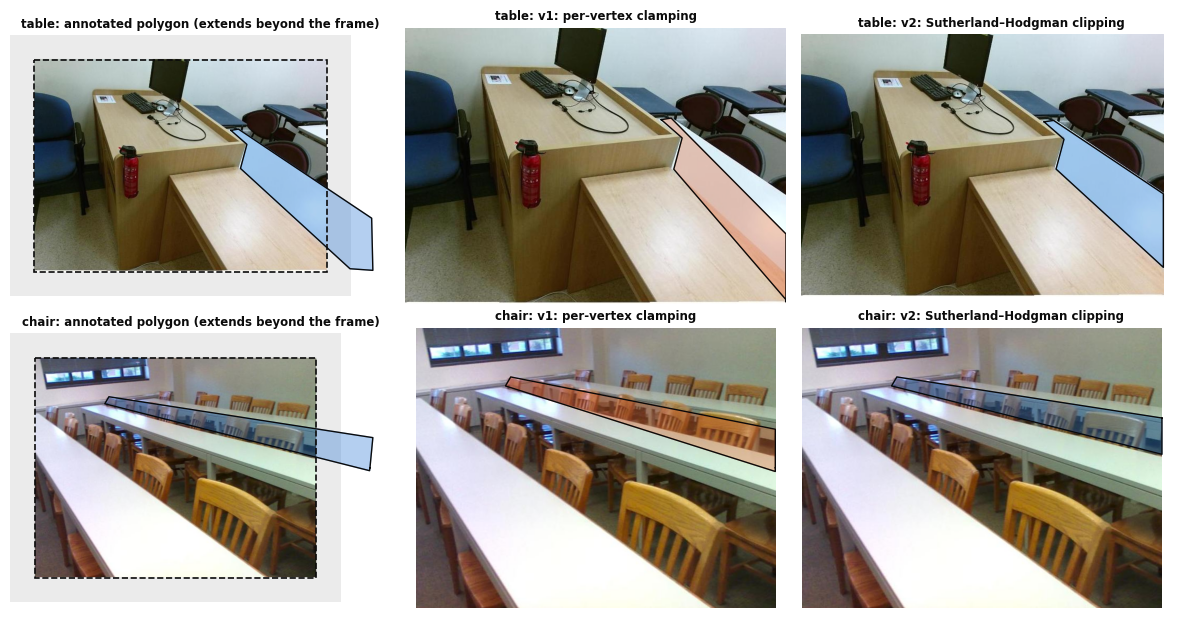

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
for row, name in zip(axes, [n for n in ("bed", "sofa", "table", "chair", "desk") if n in examples][:2]):
    key, w, h, polys, new = examples[name]
    rgb = sd.read_rgb(DATASET_ROOT / img_by_key[key]["file_name"])
    pad = 60
    canvas = np.full((h + 2 * pad, w + 2 * pad, 3), 235, np.uint8)
    canvas[pad:pad + h, pad:pad + w] = rgb
    shown = (("annotated polygon (extends beyond the frame)", polys, pad, canvas),
             ("v1: per-vertex clamping", [clamp_v1(p, w, h) for p in polys], 0, rgb),
             ("v2: Sutherland–Hodgman clipping", new, 0, rgb))
    for ax, (title, ps, off, img) in zip(row, shown):
        ax.imshow(img)
        for p in ps:
            q = np.asarray(p, float).reshape(-1, 2) + off
            ax.fill(q[:, 0], q[:, 1], color=C_DROP if "v1" in title else C_STD, alpha=0.35)
            ax.plot(np.r_[q[:, 0], q[0, 0]], np.r_[q[:, 1], q[0, 1]], color=C_TEXT, lw=1)
        if off:
            ax.add_patch(plt.Rectangle((off, off), w, h, fill=False, ls="--", lw=1.2, color=C_TEXT))
        ax.set_title(f"{name}: {title}", fontsize=8.5); ax.axis("off")
plt.tight_layout(); savefig(fig, "fig_polygon_clipping.png"); plt.show()

---
## 6. COCO file, class and size distributions

`outputs/sunrgbd_instances_all.json` holds every kept object of every class
(paths relative to the dataset root; extra image fields: depth file, sensor,
collection, intrinsics, `group_key`). Image ids are stable across rebuilds
(known scenes keep their id).

In [10]:
from pycocotools.coco import COCO
_c = COCO(); _c.dataset = coco; _c.createIndex()          # readable by the standard tooling

anns_df = pd.DataFrame({"category": [cat_name[a["category_id"]] for a in coco["annotations"]],
                        "image_id": [a["image_id"] for a in coco["annotations"]],
                        "area": [a["area"] for a in coco["annotations"]]})
per_cat = (anns_df.groupby("category").agg(n_instances=("area", "size"), n_images=("image_id", "nunique"),
                                           median_area=("area", "median"))
           .sort_values("n_instances", ascending=False))
per_cat["share_%"] = (per_cat.n_instances / len(anns_df) * 100).round(2)
per_cat.to_csv(OUT_DIR / "class_distribution.csv")

size_bins = pd.cut(anns_df.area, [0, 32 ** 2, 96 ** 2, np.inf], labels=["small", "medium", "large"])
std = anns_df[anns_df.category.isin(sd.STANDARD_10_CLASSES)]
size_tbl = pd.DataFrame({"all": size_bins.value_counts(), "std10": size_bins[std.index].value_counts()}).sort_index()
size_tbl.index.name = "area"
for col in ("all", "std10"):
    size_tbl[f"{col}_share_%"] = (size_tbl[col] / size_tbl[col].sum() * 100).round(1)
size_tbl.to_csv(OUT_DIR / "size_distribution.csv")
display(per_cat.loc[sd.STANDARD_10_CLASSES]); display(size_tbl)

creating index...
index created!


,n_instances,n_images,median_area,share_%
category,,,,
bed,1404,1064,42235.5,1.12
chair,17643,5830,6749.0,14.09
sofa,2168,1284,18196.0,1.73
table,7534,4792,13686.0,6.02
desk,2541,1458,13979.0,2.03
toilet,262,250,22244.0,0.21
dresser,644,458,16602.5,0.51
nightstand,416,359,5764.5,0.33
bookshelf,724,523,11732.5,0.58


,all,std10,all_share_%,std10_share_%
area,,,,
small,24207,3438,19.3,10.3
medium,57110,12761,45.6,38.1
large,43922,17284,35.1,51.6


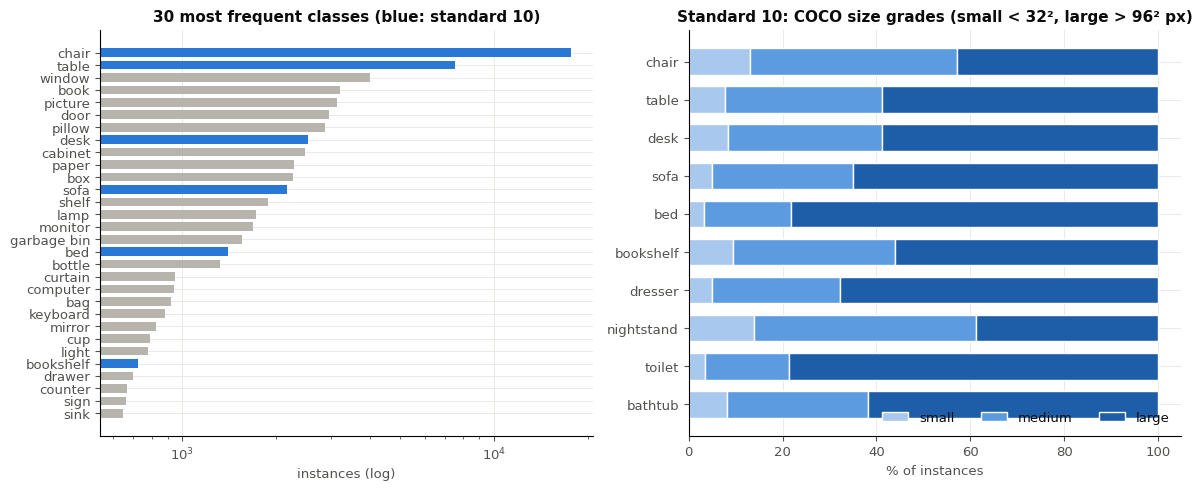

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
top = per_cat.head(30).iloc[::-1]
axes[0].barh(top.index, top.n_instances, height=0.7,
             color=[C_STD if n in sd.STANDARD_10_CLASSES else C_OTHER for n in top.index])
axes[0].set_xscale("log"); axes[0].set_xlabel("instances (log)")
axes[0].set_title("30 most frequent classes (blue: standard 10)")

order_ = per_cat.loc[sd.STANDARD_10_CLASSES].sort_values("n_instances").index
shares = (pd.crosstab(std.category, size_bins[std.index], normalize="index") * 100).reindex(order_)
left = np.zeros(len(shares))
for col, colr in zip(["small", "medium", "large"], ["#a8c8ee", "#5d9be1", "#1e5da8"]):
    axes[1].barh(shares.index, shares[col], left=left, color=colr, height=0.7,
                 edgecolor="white", linewidth=1, label=col)
    left += shares[col].values
axes[1].set_xlabel("% of instances"); axes[1].legend(frameon=False, ncol=3, loc="lower right")
axes[1].set_title("Standard 10: COCO size grades (small < 32², large > 96² px)")
plt.tight_layout(); savefig(fig, "fig_class_distribution.png"); plt.show()

---
## 7. Leak-free grouping

A random split over frames leaks: near-identical views of the same room end up
in train and test, and test AP measures memorization. The audit of the v1 split
found four mechanisms (numbers for the v1 split, from the dataset analysis):
(a) SUN3D sites scanned several times — 136 test images shared a site with
train; (b) long SUN3D scans split frame-wise (already fixed before v2);
(c) simultaneous captures by different sensors (kv2 / xtion / realsense on
2014-12-18) — 113 of 235 kv2–xtion pairs were in different subsets;
(d) kv2 kinect2data — 377 of 455 test images had a train frame of the same
device within 60 s (the official SUN RGB-D split has the same issue).

`sd.assign_groups` (v2) unions all frames that may show the same place:

* **(a) SUN3D site** — all scans of one location directory, with a trailing
  scan index removed (`brown_cs_4` → `brown_cs`): repeated scans of one building
  are stored as separate locations (visually confirmed matches between
  brown_cs_1/2, 4/5, 8/9 and brown_cogsci_2/7);
* **(b–d) capture sessions** — kv2 (align_kv2, kinect2data), xtion_align_data and
  realsense names carry the capture time (and the device serial). All these
  frames form one time-ordered stream across devices, cut wherever two
  consecutive frames are more than **120 s** apart. Within a room the cadence is
  10–60 s (81% of consecutive same-device gaps are ≤ 60 s, 90% ≤ 120 s, see the
  histogram); a visual same-place test (ORB + RANSAC) showed the match rate
  of same-device pairs falling from 4.6% at ≤ 30 s to 0.4% at 1–2 min and
  ≤ 0.2% beyond. One stream across
  devices keeps the simultaneous multi-sensor captures together (kv2 and xtion
  frames match within 0–3 s; realsense clocks are off by up to a few minutes);
* **(e) kv1 near-duplicates** — NYUdata and b3dodata have no capture metadata
  (sequential ids only), so neighbouring frames (id distance ≤ 5) are linked when
  they show the same place (≥ 40 ORB + RANSAC inliers; unrelated frames reach
  ~22): 545 of the 2,000 kv1 frames fall into 240 near-duplicate groups.

Every other collection falls back to the pre-v2 rule (none does in SUN RGB-D).

In [12]:
images = coco["images"]
gsize = Counter(im["group_key"] for im in images)
g_df = pd.DataFrame({"rel_key": [im["rel_key"] for im in images],
                     "group_key": [im["group_key"] for im in images],
                     "collection": [im["collection"] for im in images]})
g_df["size"] = g_df.group_key.map(gsize)
g_df["rule"] = np.select(
    [g_df.group_key.str.startswith("capture/"),
     g_df.collection.isin(sd.SEQUENCE_COLLECTIONS),
     g_df.collection.isin(sd.NO_METADATA_COLLECTIONS) & (g_df["size"] > 1)],
    ["(b-d) capture session", "(a) SUN3D site", "(e) kv1 near-duplicates"], "single frame")
summary = (g_df.groupby("rule").agg(images=("rel_key", "size"), groups=("group_key", "nunique"),
                                    largest=("size", "max")))
display(summary)
sizes = pd.Series(list(gsize.values()))
print(f"{len(sizes)} groups for {len(images)} images; size median {sizes.median():.0f}, "
      f"p99 {sizes.quantile(0.99):.0f}, max {sizes.max()} ({sizes.max() / len(images):.1%}); "
      f"groups > 2% of the images: {int((sizes > 0.02 * len(images)).sum())}")
display(pd.Series(gsize).sort_values(ascending=False).head(8).to_frame("images"))

# evidence: SUN3D sites with several scans, multi-sensor pairs, kv1 links
scans = g_df[g_df.collection == "sun3ddata"].rel_key.str.rsplit("/", n=1).str[0]
site_scans = scans.groupby(scans.map(sd.sun3d_site)).nunique()
print(f"(a) SUN3D: {scans.nunique()} scans at {len(site_scans)} sites; "
      f"{(site_scans > 1).sum()} sites have several scans ({scans[scans.map(sd.sun3d_site).isin(site_scans[site_scans > 1].index)].size} frames)")
timed = sorted((t, dev, k) for k in g_df.rel_key for t, dev in [sd.parse_capture_time(k) or (None, None)] if t)
sync = sum(1 for i, (t, d, k) in enumerate(timed) for t2, d2, k2 in timed[i + 1:i + 30]
           if d2 != d and (t2 - t).total_seconds() <= 5)
print(f"(c) frame pairs of different devices captured <= 5 s apart: {sync}")
n_kv1 = (g_df.rule == "(e) kv1 near-duplicates").sum()
print(f"(e) kv1 frames in near-duplicate groups: {n_kv1} of "
      f"{g_df.collection.isin(sd.NO_METADATA_COLLECTIONS).sum()}")

,images,groups,largest
rule,,,
(a) SUN3D site,3074,166,103
(b-d) capture session,5220,487,218
(e) kv1 near-duplicates,545,240,5
single frame,1455,1455,1


2348 groups for 10294 images; size median 1, p99 51, max 218 (2.1%); groups > 2% of the images: 1


,images
capture/2014-12-18_11-31-54,218
capture/2014-12-18_16-13-46,129
capture/2014-06-28_18-27-15,125
capture/2014-12-18_15-43-26,111
capture/2014-12-18_13-56-35,109
xtion/sun3ddata/home_ac,103
xtion/sun3ddata/mit_w85,102
xtion/sun3ddata/brown_cs,97


(a) SUN3D: 270 scans at 166 sites; 49 sites have several scans (1478 frames)
(c) frame pairs of different devices captured <= 5 s apart: 434
(e) kv1 frames in near-duplicate groups: 545 of 2000


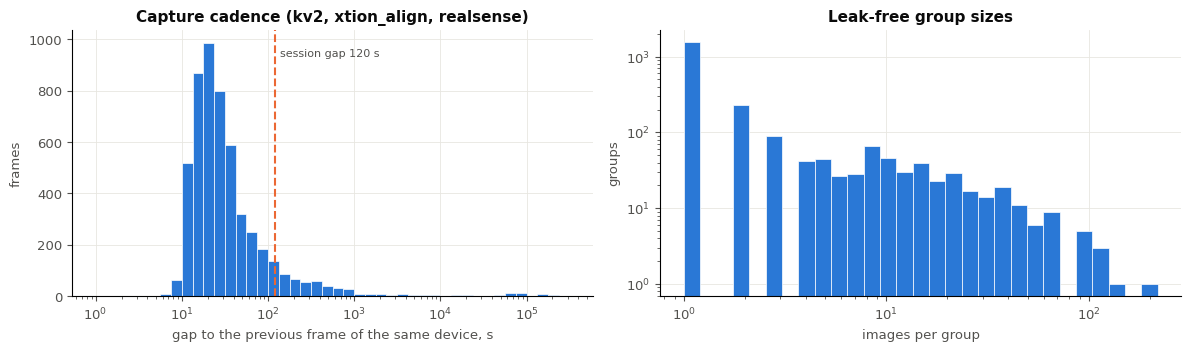

Gaps <= 60 s: 81.2%, <= 120 s: 89.8% of all consecutive frames


In [13]:
timed_df = pd.DataFrame(timed, columns=["time", "device", "rel_key"])
gaps = (timed_df.sort_values("time").groupby("device").time.diff().dt.total_seconds().dropna())
gaps = gaps[gaps > 0]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
bins = np.logspace(0, 5.5, 45)
axes[0].hist(gaps, bins=bins, color=C_STD, edgecolor="white", linewidth=0.5)
axes[0].axvline(sd.CAPTURE_GAP_S, color=C_DROP, ls="--", lw=1.5)
axes[0].text(sd.CAPTURE_GAP_S * 1.15, axes[0].get_ylim()[1] * 0.9,
             f"session gap {sd.CAPTURE_GAP_S} s", color=C_TEXT2, fontsize=8)
axes[0].set_xscale("log"); axes[0].set_xlabel("gap to the previous frame of the same device, s")
axes[0].set_ylabel("frames"); axes[0].set_title("Capture cadence (kv2, xtion_align, realsense)")
axes[1].hist(sizes, bins=np.logspace(0, np.log10(sizes.max() + 1), 30), color=C_STD,
             edgecolor="white", linewidth=0.5)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("images per group"); axes[1].set_ylabel("groups")
axes[1].set_title("Leak-free group sizes")
plt.tight_layout(); savefig(fig, "fig_grouping.png"); plt.show()
print(f"Gaps <= 60 s: {(gaps <= 60).mean():.1%}, <= {sd.CAPTURE_GAP_S} s: "
      f"{(gaps <= sd.CAPTURE_GAP_S).mean():.1%} of all consecutive frames")

In [14]:
for name, d in CONFIGS.items():
    print(f"--- {name}: " + (d / "leak_check.txt").read_text())

--- std10: Leak check — splits (dataset v2)
images 8554, groups 1994; group size: median 1, p99 51, max 197 (2.3% of images)

OK   groups spanning subsets: 0
OK   (a) SUN3D scans in >1 subset: 0
OK   (a) SUN3D sites in >1 subset: 0
OK   (c) multi-sensor pairs <= 5 s in different subsets: 0
OK   (d) same-device pairs <= 60 s in different subsets: 0
OK   (d) test images with a train frame of the same device <= 60 s: 0
OK   (b-d) timestamped pairs <= 120 s in different subsets: 0
OK   (e) kv1 near-duplicate pairs in different subsets: 0

--- min400: Leak check — splits_min400 (dataset v2)
images 9741, groups 2284; group size: median 1, p99 51, max 209 (2.1% of images)

OK   groups spanning subsets: 0
OK   (a) SUN3D scans in >1 subset: 0
OK   (a) SUN3D sites in >1 subset: 0
OK   (c) multi-sensor pairs <= 5 s in different subsets: 0
OK   (d) same-device pairs <= 60 s in different subsets: 0
OK   (d) test images with a train frame of the same device <= 60 s: 0
OK   (b-d) timestamped pairs <=

---
## 8. Stratified split

`pdp.make_splits` assigns **whole groups** to train / val / test (70 / 15 / 15,
seed 42). Each group is described by its per-class instance counts (the selected
classes plus every class of the min400 set), per-sensor image counts and image
count; groups are placed greedily (rare-class and large groups first) where the
squared relative deviation from the target counts grows least, then improved by
single-group moves and two-group swaps. The extended configs inherit the std10
assignment (`--base-assignment`) and place only their additional groups, so a
scene never changes subset between configs; min100 (41 classes, not trained) is
balanced only on the sensors and the min400 classes.

Result (std10): 5,983 / 1,284 / 1,287 images; every class and sensor share of
val/test is within a few percent of train, except `dresser` (val +15%, test +8%:
its instances are concentrated in a few large furniture-store groups). The rare
classes keep usable val/test counts (bathtub 22 / 22, toilet 39 / 39).

=== std10: {'train': 5983, 'val': 1284, 'test': 1287} images, {'train': 23390, 'val': 5050, 'test': 5043} instances; max |relative deviation| of val/test shares from train: classes 15.0%, sensors 2.5%


train   val  test  total  val_rel_dev  test_rel_dev
kind   name                                                           
class  bed           972   210   222   1404        0.001         0.059
       chair       12335  2657  2651  17643       -0.002        -0.003
       sofa         1517   326   325   2168       -0.005        -0.006
       table        5271  1132  1131   7534       -0.005        -0.005
       desk         1779   381   381   2541       -0.008        -0.007
       toilet        184    39    39    262       -0.018        -0.017
       dresser       435   108   101    644        0.150         0.077
       nightstand    288    66    62    416        0.061        -0.002
       bookshelf     506   109   109    724       -0.002        -0.001
       bathtub       103    22    22    147       -0.011        -0.009
sensor kv1          1115   239   239   1593       -0.001        -0.004
       kv2          2382   509   509   3400       -0.004        -0.007
       realsense     694   149   153    996        0.000         0.025
       xtion        1792   387   386   2565        0.006         0.001

=== min400: {'train': 6854, 'val': 1443, 'test': 1444} images, {'train': 34936, 'val': 7528, 'test': 7517} instances; max |relative deviation| of val/test shares from train: classes 15.2%, sensors 3.8%


train   val  test  total  val_rel_dev  test_rel_dev
kind   name                                                            
class  bed            972   210   222   1404        0.003         0.061
       chair        12335  2657  2651  17643       -0.000        -0.001
       sofa          1517   326   325   2168       -0.003        -0.004
       table         5271  1132  1131   7534       -0.003        -0.003
       desk          1779   381   381   2541       -0.006        -0.005
       toilet         184    39    39    262       -0.016        -0.015
       dresser        435   108   101    644        0.152         0.079
       nightstand     288    66    62    416        0.064         0.001
       bookshelf      506   109   109    724       -0.000         0.001
       bathtub        103    22    22    147       -0.009        -0.007
       cabinet       2275   488   487   3250       -0.005        -0.005
       pillow        2014   431   431   2876       -0.007        -0.005
       display       1512   322   323   2157       -0.012        -0.007
       shelf         1325   283   283   1891       -0.009        -0.007
       lamp          1205   259   260   1724       -0.003         0.003
       garbage bin   1093   233   234   1560       -0.011        -0.005
       computer       658   144   141    943        0.016        -0.004
       keyboard       618   134   133    885        0.006         0.000
       sink           452    97    97    646       -0.004        -0.003
       plant          394    87    85    566        0.025         0.003
sensor kv1           1350   292   291   1933        0.027         0.023
       kv2           2589   542   547   3678       -0.006         0.003
       realsense      759   160   166   1085        0.001         0.038
       xtion         2156   449   440   3045       -0.011        -0.031

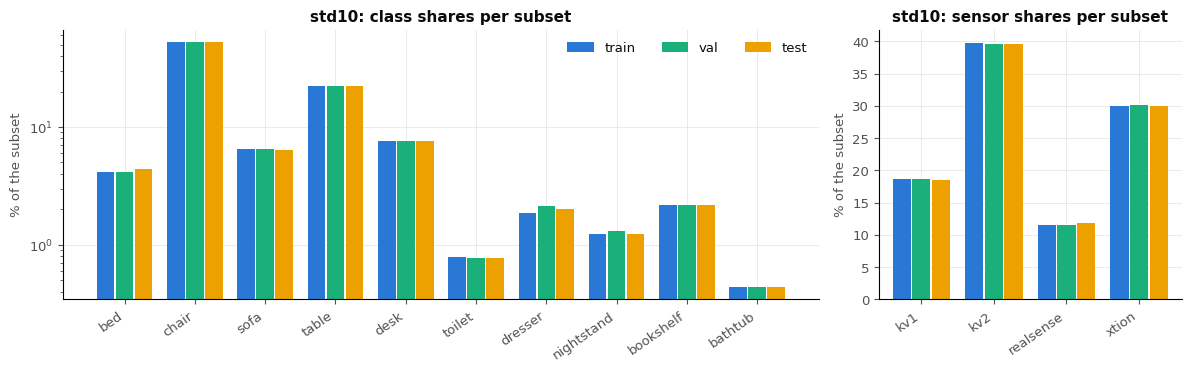

min400: all 8554 std10 scenes in the same subset: True
min100: all 8554 std10 scenes in the same subset: True


In [15]:
for name in ("std10", "min400"):
    dist = pd.read_csv(CONFIGS[name] / "split_class_distribution.csv", index_col=[0, 1])
    version = json.loads((CONFIGS[name] / "dataset_version.json").read_text())
    dev = dist[["val_rel_dev", "test_rel_dev"]].abs()
    print(f"=== {name}: {version['n_images']} images, {version['n_instances']} instances; "
          f"max |relative deviation| of val/test shares from train: classes "
          f"{dev.loc['class'].max().max():.1%}, sensors {dev.loc['sensor'].max().max():.1%}")
    display(dist[["train", "val", "test", "total", "val_rel_dev", "test_rel_dev"]])

dist = pd.read_csv(CONFIGS["std10"] / "split_class_distribution.csv", index_col=[0, 1])
share = dist[["train", "val", "test"]].div(dist[["train", "val", "test"]].groupby(level="kind").transform("sum")) * 100
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [10, 4]})
for ax, kind in zip(axes, ("class", "sensor")):
    s = share.loc[kind]; x = np.arange(len(s))
    for i, sub in enumerate(("train", "val", "test")):
        ax.bar(x + (i - 1) * 0.27, s[sub], width=0.25, color=SUBSET_COLORS[sub], label=sub)
    ax.set_xticks(x); ax.set_xticklabels(s.index, rotation=35, ha="right")
    ax.set_ylabel("% of the subset"); ax.set_yscale("log" if kind == "class" else "linear")
    ax.set_title(f"std10: {kind} shares per subset")
axes[0].legend(frameon=False, ncol=3)
plt.tight_layout(); savefig(fig, "fig_split_balance.png"); plt.show()

std_cfg = pd.read_csv(CONFIGS["std10"] / "split_assignment.csv")
for other in ("min400", "min100"):
    o = pd.read_csv(CONFIGS[other] / "split_assignment.csv").set_index("rel_key").subset
    same = (o.reindex(std_cfg.rel_key).values == std_cfg.subset.values).all()
    print(f"{other}: all {len(std_cfg)} std10 scenes in the same subset: {same}")

---
## Summary

Dataset v2 (`info.version` in every COCO file, `dataset_version.json` in every
split directory — the training notebooks check it):

| | images | instances | train / val / test images |
|---|---|---|---|
| all classes (`sunrgbd_instances_all.json`) | 10,294 | 125,239 | — |
| std10 (`splits/`) | 8,554 | 33,483 | 5,983 / 1,284 / 1,287 |
| min400, 20 classes (`splits_min400/`) | 9,741 | 49,981 | 6,854 / 1,443 / 1,444 |

* **Polygon clipping:** 49% of the std10 objects have a vertex outside the
  frame; clipping matches the exact raster (IoU ≥ 0.99 for 99.87% of them,
  ≥ 0.98 for 99.99%); per-vertex clamping had changed 2,298 std10 masks by more
  than 10% IoU (285 by more than half).
* **Recovered names:** +987 std10 instances (chair +370, table +285, sofa +162),
  +1,107 for the other min400 classes; reviewed decisions in
  `class_analysis/name_recovery_v2.csv`.
* **Leak-free groups:** 2,348 groups for 10,294 images (SUN3D sites, capture
  sessions, kv1 near-duplicates); the largest is the 2014-12-18 multi-sensor
  capture session (218 images, 2.1%). The leak check (`leak_check.txt`) finds no
  pair of related frames in different subsets for any rule in any config.

Files: `outputs/sunrgbd_instances_all.json`; `outputs/splits{,_min400,_min100}/`
with `instances_{train,val,test}.json`, `split_assignment.csv`,
`split_class_distribution.csv`, `leak_check.txt`, `dataset_version.json`;
tables `scenes_index.csv`, `name_normalization_map.csv`, `class_distribution.csv`,
`size_distribution.csv`, `depth_stats_sample.csv`.

Figures: `fig_dataset_overview.png`, `fig_depth_decoding.png`,
`fig_polygon_clipping.png`, `fig_class_distribution.png`, `fig_grouping.png`,
`fig_split_balance.png`.

For Colab: `python utils/pack_for_colab.py --root <SUNRGBD> --splits
notebooks/outputs/splits notebooks/outputs/splits_min400 --out sunrgbd_data.zip`.